In [1]:
from google.colab import drive
drive.mount('/content/drive')

from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Mounted at /content/drive


In [5]:
df_data = pd.read_csv('/content/drive/MyDrive/data.csv')
X = df_data.drop(columns=["id", "diagnosis", "Unnamed: 32"])
Y = df_data["diagnosis"]

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, ConfusionMatrixDisplay

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=123)

Accuracy: 0.98

Classification Report:
               precision    recall  f1-score   support

           B       0.99      0.99      0.99       140
           M       0.98      0.98      0.98        88

    accuracy                           0.98       228
   macro avg       0.98      0.98      0.98       228
weighted avg       0.98      0.98      0.98       228

Training accuracy: 1.0
Test accuracy: 0.9824561403508771
CV scores: [0.92982456 0.93859649 0.98245614 0.98245614 0.98230088]
Confusion Matrix:
[[138   2]
 [  2  86]]


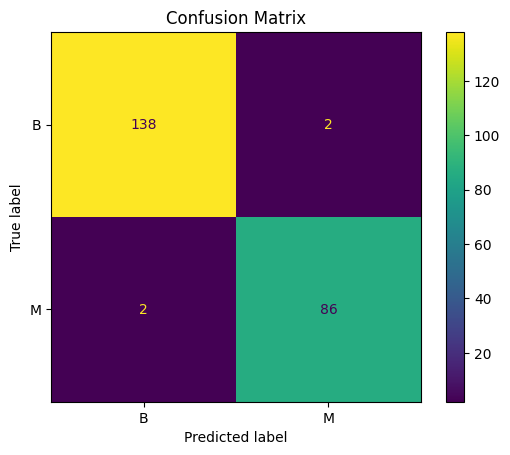

In [26]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=123)
rf_classifier.fit(X_train, Y_train)
Y_pred = rf_classifier.predict(X_test)

accuracy = accuracy_score(Y_test, Y_pred)
classification_rep = classification_report(Y_test, Y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_rep)

train_pred = rf_classifier.predict(X_train)
test_pred = rf_classifier.predict(X_test)

print("Training accuracy:", accuracy_score(Y_train, train_pred))
print("Test accuracy:", accuracy_score(Y_test, test_pred))

scores = cross_val_score(rf_classifier, X, Y, cv=5, scoring="accuracy")
print("CV scores:", scores)

#confusion Matrix
conf_matrix = confusion_matrix(Y_test, Y_pred)
print("Confusion Matrix:")
print(conf_matrix)

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=["B", "M"])
disp.plot()
plt.title("Confusion Matrix")
plt.show()
